In [1]:
from langchain_openai import ChatOpenAI
from dotenv import load_dotenv

load_dotenv()
model = ChatOpenAI(model="gpt-4o-mini")

In [2]:
from langgraph.graph import MessagesState

class State(MessagesState):
    summary: str

In [3]:
from langchain_core.messages import SystemMessage, HumanMessage, RemoveMessage

# Define the logic to call the model
def call_model(state: State):
    # Get summary if it exists
    summary = state.get("summary", "")
    
    # If there is summary, then we add it
    if summary:
        # Add summary to system message
        system_message = f"Summary of conversation earlier: {summary}"
        
        # Append summary to any newer messages
        messages = [SystemMessage(content=system_message)] + state["messages"]
    else:
        messages = state["messages"]
    
    response = model.invoke(messages)
    return {"messages": response}

In [4]:
def summarize_conversation(state: State):
    # First, we get any existing summary
    summary = state.get("summary", "")
    
    # Create our summarization prompt
    if summary:
        # A summary already exists
        summary_message = (
            f"This is summary of the conversation to date: {summary}\n\n"
            "Extend the summary by taking into account the new messages above:"
        )
    else:
        summary_message = "Create a summary of the conversation above:"
    
    # Add prompt to our history
    messages = state["messages"] + [HumanMessage(content=summary_message)]
    response = model.invoke(messages)
    
    # Delete all but the 2 most recent messages
    delete_messages = [RemoveMessage(id=m.id) for m in state["messages"][:-2]]
    return {"summary": response.content, "messages": delete_messages}

In [5]:
from langgraph.graph import END

# Determine whether to end or summarize the conversation
def should_continue(state: State):
    """Return the next node to execute."""
    messages = state['messages']
    
    # If there are more than six messages, then we summarize the conversation
    if len(messages) >= 6:
        return "summarize_conversation"
    
    # Otherwise we can just end
    return "end"

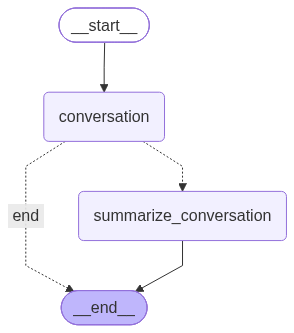

In [6]:
from IPython.display import Image, display
from langgraph.checkpoint.memory import MemorySaver
from langgraph.graph import StateGraph, START, END

# Define a new graph
workflow = StateGraph(State)

# Add nodes
workflow.add_node("conversation", call_model)
workflow.add_node("summarize_conversation", summarize_conversation)

# Set the entrypoint as conversation
workflow.add_edge(START, "conversation")

# Add conditional edge from conversation node
workflow.add_conditional_edges("conversation", should_continue, {
    "summarize_conversation": "summarize_conversation",
    "end": END
})

# After summarization, end the graph
workflow.add_edge("summarize_conversation", END)

# Compile with checkpointer for memory
memory = MemorySaver()
graph = workflow.compile(checkpointer=memory)

# Visualize the graph
display(Image(graph.get_graph().draw_mermaid_png()))

In [7]:
# Create a thread (conversation session)
config = {"configurable": {"thread_id": "1"}}

# Start conversation
input_message = HumanMessage(content="hi! I'm Siva")
output = graph.invoke({"messages": [input_message]}, config)
for m in output['messages'][-1:]:
    m.pretty_print()

input_message = HumanMessage(content="what's my name?")
output = graph.invoke({"messages": [input_message]}, config)
for m in output['messages'][-1:]:
    m.pretty_print()

input_message = HumanMessage(content="i Love python !")
output = graph.invoke({"messages": [input_message]}, config)
for m in output['messages'][-1:]:
    m.pretty_print()

================================== Ai Message ==================================

Hi Siva! How can I assist you today?
================================== Ai Message ==================================

Your name is Siva. How can I help you today?
================================== Ai Message ==================================

That's great to hear, Siva! Python is a powerful and versatile programming language. What do you enjoy most about Python, or are you working on any specific projects?


In [8]:
graph.get_state(config).values.get("summary", "")

'In the conversation, Siva introduced himself and expressed his love for Python. I responded positively and asked about what he enjoys most about the language or if he was working on any particular projects.'

In [9]:
input_message = HumanMessage(content="tell me about elon musk")
output = graph.invoke({"messages": [input_message]}, config)
for m in output['messages'][-1:]:
    m.pretty_print()

================================== Ai Message ==================================

Elon Musk is a prominent entrepreneur and business magnate known for his role in several high-profile technology companies. Here are some key points about him:

1. **Early Life**: Elon Musk was born on June 28, 1971, in Pretoria, South Africa. He showed an early interest in computing and technology, learning to program at a young age.

2. **Education**: He attended Queen's University in Canada before transferring to the University of Pennsylvania, where he earned degrees in both physics and economics.

3. **Zip2**: In 1996, Musk co-founded Zip2, a software company that provided business directories and maps. Compaq acquired it in 1999 for nearly $300 million.

4. **X.com and PayPal**: Musk then founded X.com, an online payment company. X.com eventually became PayPal, which was sold to eBay for $1.5 billion in stock in 2002.

5. **SpaceX**: In 2002, Musk founded SpaceX (Space Exploration Technologies Corp.

In [10]:
graph.get_state(config).values.get("summary", "")

'In the conversation, Siva introduced himself and expressed his love for Python. I responded positively and asked about what he enjoys most about the language or if he was working on any particular projects.'

In [11]:
pip install langchain-tavily

Note: you may need to restart the kernel to use updated packages.


In [12]:
from langchain_tavily import TavilySearch
from langchain_openai import ChatOpenAI
from langchain_core.messages import SystemMessage

tools = [TavilySearch(max_results=3)]

# Tool-bound model for the conversation step only.
# summarize_conversation keeps using the plain `model` from section 1.
model_with_tools = ChatOpenAI(model="gpt-4o-mini", temperature=0).bind_tools(tools)

def call_model_with_tools(state: State):
    summary = state.get("summary", "")

    if summary:
        system_message = f"Summary of conversation earlier: {summary}"
        messages = [SystemMessage(content=system_message)] + state["messages"]
    else:
        messages = state["messages"]

    response = model_with_tools.invoke(messages)
    return {"messages": response}

In [13]:
from langgraph.graph import StateGraph, START, END

summarization_builder = StateGraph(State)
summarization_builder.add_node("conversation", call_model_with_tools)
summarization_builder.add_node("summarize_conversation", summarize_conversation)

summarization_builder.add_edge(START, "conversation")
summarization_builder.add_conditional_edges("conversation", should_continue, {
    "summarize_conversation": "summarize_conversation",
    "end": END
})
summarization_builder.add_edge("summarize_conversation", END)

# No checkpointer: this compiled graph is a node inside the parent.
summarization_subgraph = summarization_builder.compile()

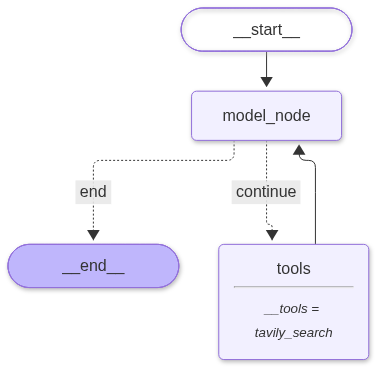

In [14]:
from langgraph.prebuilt import ToolNode
from langgraph.checkpoint.memory import MemorySaver

def where_to_go(state: State):
    last_message = state["messages"][-1]
    if last_message.tool_calls:
        return "continue"
    else:
        return "end"

parent_builder = StateGraph(State)

# Basics guide: workflow.add_node("agent", function_1)
# function_1 was the model call. Here that node is named model_node.
parent_builder.add_node("model_node", summarization_subgraph)
parent_builder.add_node("tools", ToolNode(tools=tools))

parent_builder.add_conditional_edges("model_node", where_to_go, {
    "continue": "tools",
    "end": END
})
parent_builder.add_edge("tools", "model_node")
parent_builder.set_entry_point("model_node")

parent_memory = MemorySaver()
parent_app = parent_builder.compile(checkpointer=parent_memory)
parent_app

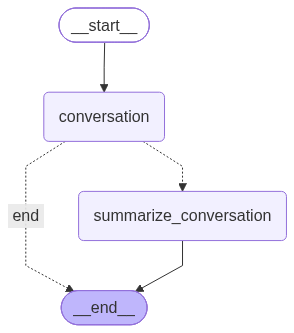

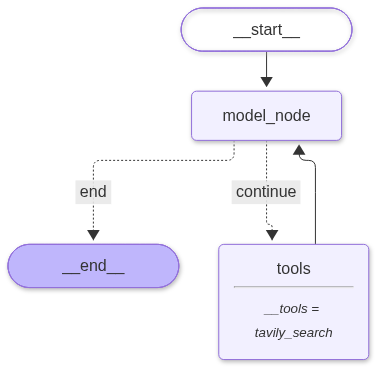

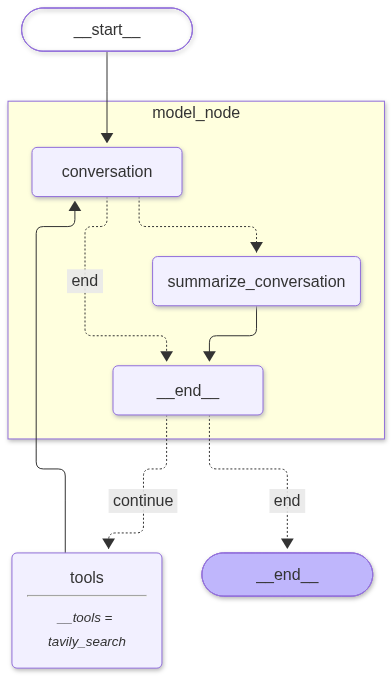

In [15]:
from IPython.display import Image, display

# Summarization subgraph by itself
display(Image(summarization_subgraph.get_graph().draw_mermaid_png()))

# Parent graph: model_node is a single node
display(Image(parent_app.get_graph().draw_mermaid_png()))

# Parent graph with the subgraph expanded
display(Image(parent_app.get_graph(xray=1).draw_mermaid_png()))

# If PNG rendering fails, print Mermaid text and paste it into https://mermaid.live
# print(parent_app.get_graph(xray=1).draw_mermaid())

In [16]:
config = {"configurable": {"thread_id": "subgraph-1"}}

input_message = HumanMessage(content="What are the latest developments in LangGraph?")
output = parent_app.invoke({"messages": [input_message]}, config)
for m in output["messages"][-1:]:
    m.pretty_print()

input_message = HumanMessage(content="hi! I'm Siva")
output = parent_app.invoke({"messages": [input_message]}, config)
for m in output["messages"][-1:]:
    m.pretty_print()

input_message = HumanMessage(content="what's my name?")
output = parent_app.invoke({"messages": [input_message]}, config)
for m in output["messages"][-1:]:
    m.pretty_print()

input_message = HumanMessage(content="I love Python!")
output = parent_app.invoke({"messages": [input_message]}, config)
for m in output["messages"][-1:]:
    m.pretty_print()

parent_app.get_state(config).values.get("summary", "")

================================== Ai Message ==================================

Here are the latest developments in LangGraph:

1. **New Features and Updates**:
   - LangGraph has introduced several updates in its recent versions (1.1 and 1.2), including new features such as per-node timeout settings and retry policies for nodes that make API calls. This allows for more granular control over how each node behaves in the graph.
   - The introduction of model profiles provides detailed information about the models being used, including input/output token limits and capabilities like tool calling and structured outputs.

2. **LangGraph Studio**:
   - LangGraph Studio has been launched as a visual interface for workflow development. This IDE allows users to design and build workflows graphically, making it more accessible for beginners and improving collaboration among developers.

3. **Enhanced Capabilities**:
   - Future developments include enhanced natural language processing (NLP) c

'Here’s the extended summary of our conversation to date, including the latest messages:\n\n1. **Inquiry About LangGraph**: You asked about the latest developments in LangGraph.\n\n2. **Latest Developments**:\n   - New features in LangGraph versions 1.1 and 1.2, including per-node timeout settings and retry policies for API calls.\n   - Introduction of model profiles for detailed information on models being used.\n   - Launch of LangGraph Studio, a visual IDE for easier workflow design and collaboration.\n   - Future enhancements in natural language processing (NLP) and machine learning capabilities, along with support for more platforms.\n   - Recent releases and updates listed on GitHub, with the latest version noted as 1.2.15.\n\n3. **User Introduction**: You introduced yourself as Siva.\n\n4. **Name Confirmation**: I confirmed that your name is Siva upon your query.\n\n5. **Interest in Python**: You expressed your love for Python, mentioning it as a versatile and powerful programmi